In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\HP\auspify-ml-internship\data\netflix_clean.csv")

print(df[["release_year", "year_added", "month_added", "duration_value"]].describe().round(1))
print(df.groupby("type")["duration_value"].describe().round(1))

       release_year  year_added  month_added  duration_value
count        8790.0      8790.0       8790.0          8790.0
mean         2014.2      2018.9          6.7            69.9
std             8.8         1.6          3.4            50.8
min          1925.0      2008.0          1.0             1.0
25%          2013.0      2018.0          4.0             2.0
50%          2017.0      2019.0          7.0            88.5
75%          2019.0      2020.0         10.0           106.0
max          2021.0      2021.0         12.0           312.0
          count  mean   std  min   25%   50%    75%    max
type                                                      
Movie    6126.0  99.6  28.3  3.0  87.0  98.0  114.0  312.0
TV Show  2664.0   1.8   1.6  1.0   1.0   1.0    2.0   17.0


In [2]:
df["movie_minutes"] = np.where(df["type"] == "Movie", df["duration_value"], 0)
df["tv_seasons"] = np.where(df["type"] == "TV Show", df["duration_value"], 0)

print(df[["type", "duration", "movie_minutes", "tv_seasons"]].sample(6, random_state=1))
print(df[["movie_minutes", "tv_seasons"]].describe().round(1))

         type   duration  movie_minutes  tv_seasons
7237  TV Show   1 Season              0           1
6011    Movie    121 min            121           0
6956  TV Show   1 Season              0           1
6703  TV Show   1 Season              0           1
6596  TV Show  5 Seasons              0           5
1064    Movie     84 min             84           0
       movie_minutes  tv_seasons
count         8790.0      8790.0
mean            69.4         0.5
std             51.5         1.2
min              0.0         0.0
25%              0.0         0.0
50%             88.5         0.0
75%            106.0         1.0
max            312.0        17.0


In [3]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# country: top 10 + Other
top_countries = df["country"].value_counts().head(10).index
df["country_grp"] = df["country"].where(df["country"].isin(top_countries), "Other")

# director flag
df["director_known"] = (df["director"] != "Unknown").astype(int)

# 12 most common genres as 0/1 flags
all_genres = df["listed_in"].str.split(", ").explode()
top_genres = all_genres.value_counts().head(12).index
for g in top_genres:
    df["g_" + g] = df["listed_in"].apply(lambda s: int(g in s.split(", ")))
genre_cols = ["g_" + g for g in top_genres]

num_cols = ["release_year", "year_added", "movie_minutes", "tv_seasons"]
cat_cols = ["type", "rating", "country_grp"]
flag_cols = ["director_known"] + genre_cols

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(), cat_cols),
    ("flags", "passthrough", flag_cols),
])
X = pre.fit_transform(df)

print(X.shape)
print(list(top_genres))

(8790, 44)
['International Movies', 'Dramas', 'Comedies', 'International TV Shows', 'Documentaries', 'Action & Adventure', 'TV Dramas', 'Independent Movies', 'Children & Family Movies', 'Romantic Movies', 'Thrillers', 'TV Comedies']


C:\Users\HP\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HP\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\HP\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\HP\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:

2 47441 0.292
3 43263 0.174
4 38384 0.181
5 35177 0.19
6 33238 0.176
7 31440 0.146
8 30245 0.143
9 29147 0.143
10 28346 0.138


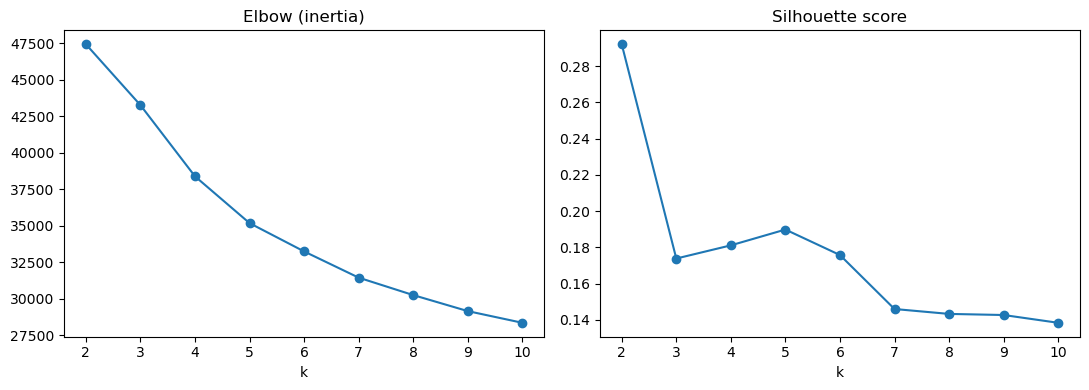

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, labels, sample_size=3000, random_state=42))
    print(k, round(inertias[-1]), round(sils[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("../outputs/task4_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# k = 2: is it just Movie vs TV Show?
km2 = KMeans(n_clusters=2, n_init=10, random_state=42)
df["cluster_k2"] = km2.fit_predict(X)
print(pd.crosstab(df["cluster_k2"], df["type"]))

# k = 5: the segmentation we'll interpret
km5 = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = km5.fit_predict(X)
print(df["cluster"].value_counts().sort_index())
print(pd.crosstab(df["cluster"], df["type"]))

type        Movie  TV Show
cluster_k2                
0            6126        2
1               0     2662
cluster
0     577
1    2288
2    3273
3     252
4    2400
Name: count, dtype: int64
type     Movie  TV Show
cluster                
0          564       13
1         2286        2
2         3273        0
3            0      252
4            3     2397


In [6]:
# numeric profile
print(df.groupby("cluster")[["release_year", "year_added", "movie_minutes", "tv_seasons", "director_known"]].mean().round(2))

# genre profile: share of each cluster tagged with each top genre
print(df.groupby("cluster")[genre_cols].mean().round(2).T)

# most common rating and country per cluster
for c in sorted(df["cluster"].unique()):
    sub = df[df["cluster"] == c]
    print(c, "| rating:", sub["rating"].value_counts().head(2).to_dict(),
          "| country:", sub["country_grp"].value_counts().head(2).to_dict())

         release_year  year_added  movie_minutes  tv_seasons  director_known
cluster                                                                     
0             1988.16     2019.28         113.24        0.03            0.97
1             2014.77     2017.25          96.34        0.00            0.97
2             2016.19     2019.88          99.06        0.00            0.97
3             2015.25     2019.03           0.00        5.68            0.08
4             2017.03     2018.93           0.02        1.34            0.09
cluster                        0     1     2     3     4
g_International Movies      0.32  0.47  0.46  0.00  0.00
g_Dramas                    0.41  0.38  0.41  0.00  0.00
g_Comedies                  0.34  0.22  0.30  0.00  0.00
g_International TV Shows    0.00  0.00  0.00  0.21  0.54
g_Documentaries             0.05  0.20  0.12  0.00  0.00
g_Action & Adventure        0.30  0.11  0.13  0.00  0.00
g_TV Dramas                 0.00  0.00  0.00  0.36  0.28
g_Ind

variance explained: [0.32  0.145] | total: 0.465


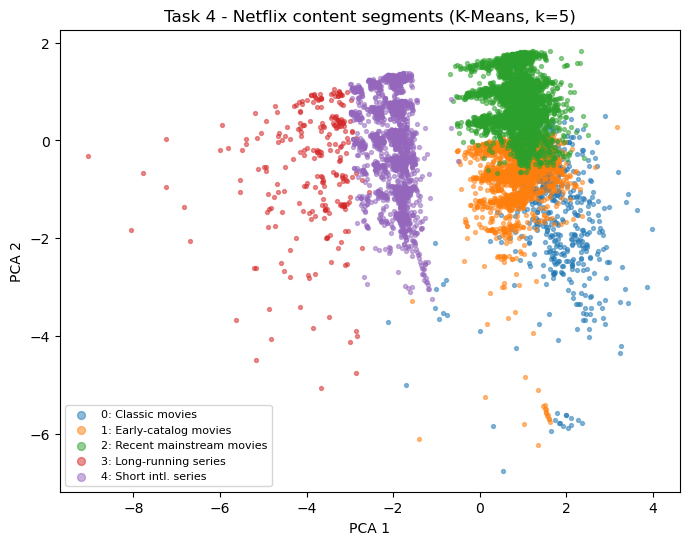

In [7]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X)
print("variance explained:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))

names = {0: "Classic movies", 1: "Early-catalog movies", 2: "Recent mainstream movies",
         3: "Long-running series", 4: "Short intl. series"}

plt.figure(figsize=(8, 6))
for c in range(5):
    m = df["cluster"] == c
    plt.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.5, label=f"{c}: {names[c]}")
plt.legend(markerscale=2, fontsize=8)
plt.xlabel("PCA 1"); plt.ylabel("PCA 2")
plt.title("Task 4 - Netflix content segments (K-Means, k=5)")
plt.savefig("../outputs/task4_clusters.png", dpi=150, bbox_inches="tight")
plt.show()